# One-time final test

This notebook runs the frozen final models once. It uses the cutoffs and feature setup in `reports/final_setup.csv`, seed 42, and the fixed settings in `docs/FINAL_SETUP.md`. Running the first code cell creates `reports/final_test.lock`; it will refuse to run again after that. No tuning or cutoff changes are performed.

## 1. Run the one-time final test

The runner fits one fresh model per setup row on all cleaned training rows, predicts once on the cleaned Imelda file, and saves probabilities and metrics. The dummy baseline is included as an experiment/reference at 0.5.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display

project_root = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / "src" / "config.py").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Could not locate the project root.")

sys.path.insert(0, str(project_root))

from src.final_test import run_final_test

final_results = run_final_test()
display(final_results)

logistic_regression_no_rain: fitted and predicted once in 0.4 seconds.


lightgbm_no_rain: fitted and predicted once in 1.3 seconds.


mlp_no_rain: fitted and predicted once in 41.9 seconds.


cnn_hybrid: fitted and predicted once in 466.5 seconds.


cnn_tile_only: fitted and predicted once in 419.0 seconds.


Final test completed in 929.3 seconds. Results: C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\final_test_results.csv


,model,role,cutoff_type,cutoff,accuracy,precision,recall,f1,roc_auc,pr_auc,tn,fp,fn,tp
0,logistic_regression_no_rain,final,frozen,0.44,0.694740,0.663122,0.812538,0.730266,0.751109,0.716798,5395,4023,1827,7919
1,logistic_regression_no_rain,final,default_0.5,0.50,0.688113,0.680629,0.728607,0.703801,0.751109,0.716798,6086,3332,2645,7101
2,lightgbm_no_rain,final,frozen,0.50,0.819923,0.797636,0.865483,0.830176,0.889570,0.860290,7278,2140,1311,8435
3,lightgbm_no_rain,final,default_0.5,0.50,0.819923,0.797636,0.865483,0.830176,0.889570,0.860290,7278,2140,1311,8435
4,mlp_no_rain,final,frozen,0.47,0.768890,0.740349,0.840242,0.787139,0.842873,0.812079,6546,2872,1557,8189
5,mlp_no_rain,final,default_0.5,0.50,0.766959,0.750190,0.812231,0.779978,0.842873,0.812079,6782,2636,1830,7916
6,cnn_hybrid,final,frozen,0.47,0.794980,0.772561,0.845885,0.807562,0.874579,0.853405,6991,2427,1502,8244
7,cnn_hybrid,final,default_0.5,0.50,0.794145,0.781465,0.826288,0.803252,0.874579,0.853405,7166,2252,1693,8053
8,cnn_tile_only,experiment only,frozen,0.38,0.683260,0.638092,0.871434,0.736728,0.768095,0.748273,4601,4817,1253,8493
9,cnn_tile_only,experiment only,default_0.5,0.50,0.701472,0.692234,0.743587,0.716992,0.768095,0.748273,6196,3222,2499,7247


**My observations:** The single run fitted and predicted all six models once on 19,164 cleaned test rows. It took 929.3 seconds (about 15.5 minutes), and the completed lock now prevents another run.

## 2. Compare final metrics

Show frozen-cutoff metrics first for the four final models, followed by experiment/reference models. The 0.5 rows are reference scores only; they do not replace the frozen cutoffs.

In [2]:
results_path = project_root / "reports" / "final_test_results.csv"
result_table = pd.read_csv(results_path)
model_order = [
    "logistic_regression_no_rain",
    "lightgbm_no_rain",
    "mlp_no_rain",
    "cnn_hybrid",
    "cnn_tile_only",
    "dummy",
]
result_table["_model_order"] = result_table["model"].map(
    {name: index for index, name in enumerate(model_order)}
)
display(
    result_table.sort_values(["_model_order", "cutoff_type"])
    .drop(columns="_model_order")
    .reset_index(drop=True)
)

,model,role,cutoff_type,cutoff,accuracy,precision,recall,f1,roc_auc,pr_auc,tn,fp,fn,tp
0,logistic_regression_no_rain,final,default_0.5,0.50,0.688113,0.680629,0.728607,0.703801,0.751109,0.716798,6086,3332,2645,7101
1,logistic_regression_no_rain,final,frozen,0.44,0.694740,0.663122,0.812538,0.730266,0.751109,0.716798,5395,4023,1827,7919
2,lightgbm_no_rain,final,default_0.5,0.50,0.819923,0.797636,0.865483,0.830176,0.889570,0.860290,7278,2140,1311,8435
3,lightgbm_no_rain,final,frozen,0.50,0.819923,0.797636,0.865483,0.830176,0.889570,0.860290,7278,2140,1311,8435
4,mlp_no_rain,final,default_0.5,0.50,0.766959,0.750190,0.812231,0.779978,0.842873,0.812079,6782,2636,1830,7916
5,mlp_no_rain,final,frozen,0.47,0.768890,0.740349,0.840242,0.787139,0.842873,0.812079,6546,2872,1557,8189
6,cnn_hybrid,final,default_0.5,0.50,0.794145,0.781465,0.826288,0.803252,0.874579,0.853405,7166,2252,1693,8053
7,cnn_hybrid,final,frozen,0.47,0.794980,0.772561,0.845885,0.807562,0.874579,0.853405,6991,2427,1502,8244
8,cnn_tile_only,experiment only,default_0.5,0.50,0.701472,0.692234,0.743587,0.716992,0.768095,0.748273,6196,3222,2499,7247
9,cnn_tile_only,experiment only,frozen,0.38,0.683260,0.638092,0.871434,0.736728,0.768095,0.748273,4601,4817,1253,8493


**My observations:** At the frozen cutoffs, LightGBM reached 0.8655 recall. Logistic regression was 0.8125, the MLP 0.8402, and the hybrid CNN 0.8459. Tile-only was 0.8714 but is experiment-only; the dummy's 1.0000 recall comes from predicting every row as flooded.

## 3. Confusion matrices for final models

Each matrix uses that model's frozen cutoff. Rows are actual classes and columns are predicted classes; the counts are read from the saved final metrics.

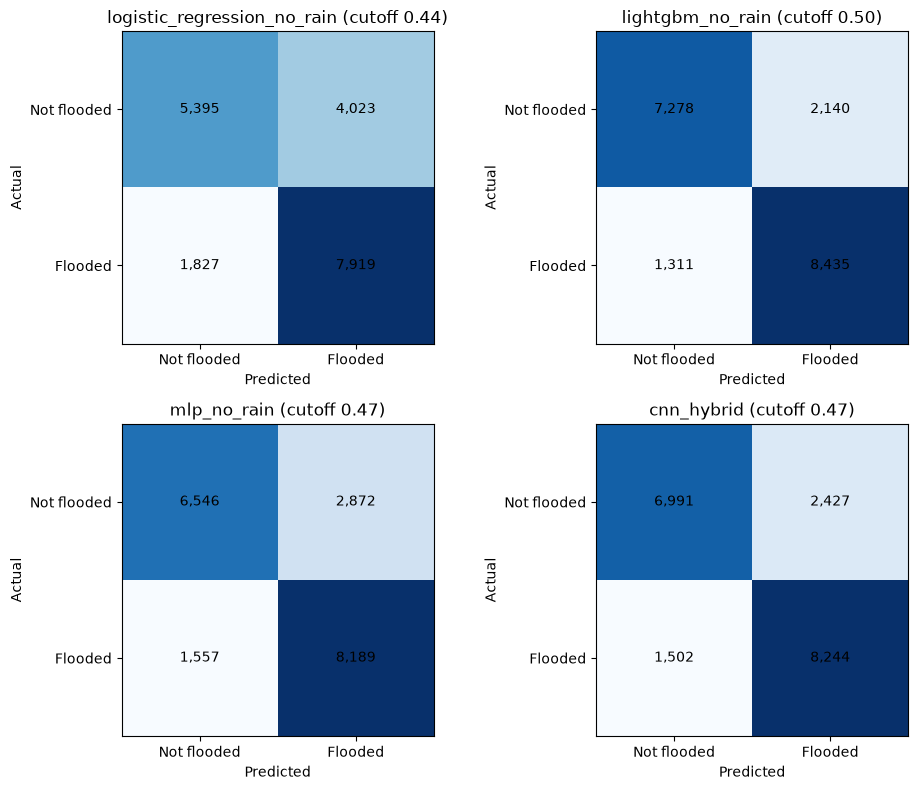

In [3]:
import matplotlib.pyplot as plt
import numpy as np

final_names = [
    "logistic_regression_no_rain",
    "lightgbm_no_rain",
    "mlp_no_rain",
    "cnn_hybrid",
]
frozen = result_table.loc[
    result_table["cutoff_type"].eq("frozen")
    & result_table["model"].isin(final_names)
].set_index("model")
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, name in zip(axes.ravel(), final_names):
    row = frozen.loc[name]
    matrix = np.array([[row.tn, row.fp], [row.fn, row.tp]], dtype=int)
    image = ax.imshow(matrix, cmap="Blues")
    for (r, c), count in np.ndenumerate(matrix):
        ax.text(c, r, f"{count:,}", ha="center", va="center")
    ax.set_xticks([0, 1], labels=["Not flooded", "Flooded"])
    ax.set_yticks([0, 1], labels=["Not flooded", "Flooded"])
    ax.set_title(f"{name} (cutoff {row.cutoff:.2f})")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
fig.tight_layout()
plt.show()

**My observations:** Among the four final models, LightGBM had the fewest false positives (2,140) and false negatives (1,311). The dummy had zero false negatives but 9,418 false positives because it predicted every test row as flooded.

## 4. ROC and precision-recall curves

The curves compare only the four final models. Each saved probability file is loaded once for plotting; no model is fit or asked to predict again.

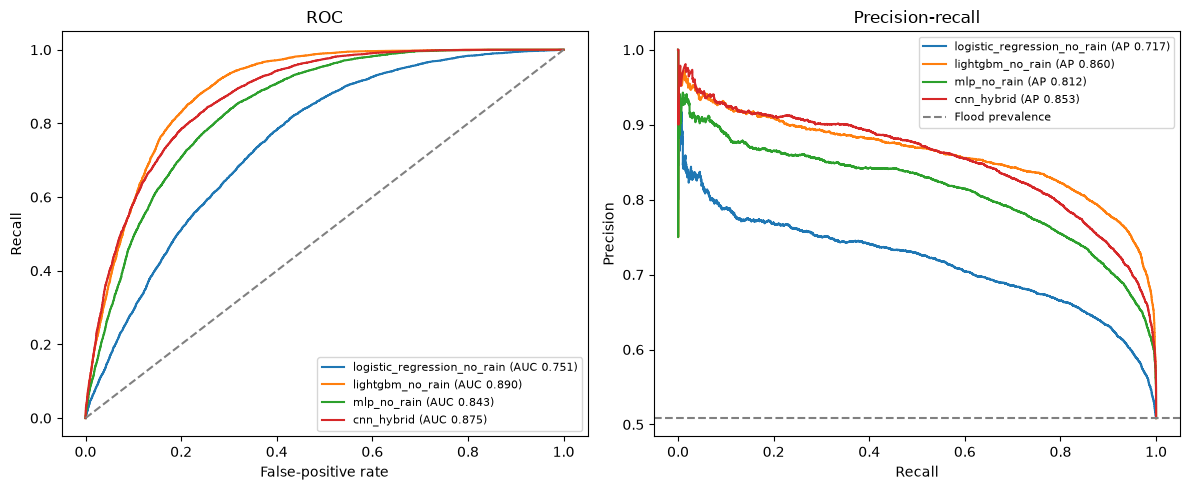

In [4]:
from sklearn.metrics import precision_recall_curve, roc_curve

reports_dir = project_root / "reports"
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name in final_names:
    pred = pd.read_csv(reports_dir / f"final_test_predictions_{name}.csv")
    fpr, tpr, _ = roc_curve(pred.y_true, pred.y_prob)
    precision, recall, _ = precision_recall_curve(pred.y_true, pred.y_prob)
    row = frozen.loc[name]
    axes[0].plot(fpr, tpr, label=f"{name} (AUC {row.roc_auc:.3f})")
    axes[1].plot(recall, precision, label=f"{name} (AP {row.pr_auc:.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set(xlabel="False-positive rate", ylabel="Recall", title="ROC")
axes[1].axhline(
    pred.y_true.mean(), linestyle="--", color="gray", label="Flood prevalence"
)
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall")
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

**My observations:** LightGBM had the strongest final-model ROC-AUC (0.8896) and PR-AUC (0.8603). The hybrid CNN was next on these curves, with ROC-AUC 0.8746 and PR-AUC 0.8534.

## 5. Compare with earlier training validation

Imelda recall is measured at each frozen cutoff (0.5 for the dummy reference). Earlier area and storm recalls in `reports/results.csv` were measured at the default 0.5 threshold. ROC-AUC does not depend on a cutoff.

In [5]:
saved_cv = pd.read_csv(reports_dir / "results.csv")
previous_model_names = {
    "logistic_regression_no_rain": "logistic_regression_no_rain",
    "lightgbm_no_rain": "lightgbm_no_rain",
    "mlp_no_rain": "mlp_no_rain",
    "cnn_hybrid": "cnn_hybrid",
    "cnn_tile_only": "cnn_tile_only",
    "dummy": "dummy",
}
comparison_rows = []
for name in model_order:
    cutoff_type = "reference_0.5" if name == "dummy" else "frozen"
    imelda = result_table.loc[
        result_table.model.eq(name) & result_table.cutoff_type.eq(cutoff_type)
    ].iloc[0]
    cv_name = previous_model_names[name]
    area = saved_cv.loc[
        saved_cv.model.eq(cv_name)
        & saved_cv.split.eq("area_group")
        & saved_cv.fold.eq("mean")
    ].iloc[0]
    storm = saved_cv.loc[
        saved_cv.model.eq(cv_name)
        & saved_cv.split.eq("leave_one_storm_out")
        & saved_cv.fold.eq("mean")
    ].iloc[0]
    comparison_rows.append({
        "model": name,
        "Imelda recall at frozen/reference cutoff": imelda.recall,
        "Imelda ROC-AUC": imelda.roc_auc,
        "Area-fold recall at 0.5": area.recall,
        "Area-fold ROC-AUC": area.roc_auc,
        "Storm-fold recall at 0.5": storm.recall,
        "Storm-fold ROC-AUC": storm.roc_auc,
    })
comparison = pd.DataFrame(comparison_rows)
display(comparison)

,model,Imelda recall at frozen/reference cutoff,Imelda ROC-AUC,Area-fold recall at 0.5,Area-fold ROC-AUC,Storm-fold recall at 0.5,Storm-fold ROC-AUC
0,logistic_regression_no_rain,0.812538,0.751109,0.790242,0.780928,0.792082,0.781411
1,lightgbm_no_rain,0.865483,0.889570,0.852761,0.891287,0.884294,0.901477
2,mlp_no_rain,0.840242,0.842873,0.829115,0.853027,0.824849,0.854097
3,cnn_hybrid,0.845885,0.874579,0.831800,0.879720,0.849153,0.879087
4,cnn_tile_only,0.871434,0.768095,0.726125,0.773771,0.816290,0.769188
5,dummy,1.000000,0.500000,1.000000,0.500000,1.000000,0.500000


**My observations:** LightGBM's Imelda recall (0.8655) was between its earlier area-fold (0.8528) and storm-fold (0.8843) recalls; its Imelda ROC-AUC (0.8896) was slightly below both earlier AUCs (0.8913 and 0.9015). The other final-model comparisons are shown beside them; validation recalls were at 0.5, while Imelda recall uses each frozen cutoff.

## Limitation

Imelda shares about 3,800 grid cells with training, so this tests a new storm at mostly familiar places. Imelda rainfall (median 1.48 in) is far below training (median 8.02 in), but rainfall is not used by the final models.